# Contratos de datos y geometría ERT

**Pregunta:** ¿Qué cálculo ERT es defendible con Slagdump sin sus bytes crudos locales?

**Nivel 1 — Fundamentos**  
**Prerrequisitos:** nociones de Python; 35 min.



## Objetivos

Pregunta: ¿Qué recupera un factor de semiespacio plano en una línea Wenner sintética y qué evidencia falta para el caso Slagdump enlazado?



## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8`



## Datos

La fuente Slagdump está documentada, pero falta el archivo ERT crudo; conteos upstream son solo metadatos.


## Método

Un dato de cuatro electrodos usa corriente A/B y potencial M/N. `R=ΔV/I` (Ω), `ρₐ=KR` (Ω·m), con `K=2π/(1/AM−1/AN−1/BM+1/BN)` en m para electrodos superficiales y convención de semiespacio homogéneo. Verifique signo y orden del arreglo en el formato. El parser conserva coordenadas, índices A-B-M-N y resistencia; no infiere columnas ausentes. El ledger identifica el ejemplo Slagdump como enlazado al proveedor, pero faltan bytes `.ohm` y no hay derechos de redistribución establecidos. Por ello no se inventa pseudosección ni inversión de campo. El diagnóstico reporta preparación y grafica únicamente controles de malla, identificados como configuración, no mediciones geofísicas.

El factor geométrico convierte resistencia bajo hipótesis de semiespacio; no es resistividad verdadera a cierta profundidad. Muchas celdas afectan cada dato, con sensibilidad extensa y resolución dependiente de profundidad. Log protege positividad pero cambia el significado de suavidad. El refinamiento se juzga por predicciones estables con ajuste comparable, no por tamaño de celda solo.



### Experimento: geometría, signo y resistividad aparente

Para Wenner-α con espaciamiento `a`, el factor del semiespacio homogéneo plano es `K=2πa` y `ρa=KR`. Convierte resistencia medida; no es resistividad localizada en profundidad. Cree una muestra sintética sin semilla (no usa datos de campo ni derechos de terceros), analícela desde bytes con el parser `.ohm` estricto del producto y varíe solo el espaciamiento. Luego inyecte una resistencia negativa: verifique que el parser la conserve y que el QC del producto informe la fila en vez de borrarla silenciosamente.

In [1]:
# Ejecute el experimento documentado con la evidencia del repositorio.
import sys, numpy as np
from pathlib import Path

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
import ert

rho_true = 120.0


def wenner(spacing):
    xz = [(i * spacing, 0.0) for i in range(33)]
    resistance = rho_true / (2 * np.pi * spacing)
    rows = [f"{i + 1} {i + 4} {i + 2} {i + 3} {resistance:.12g}" for i in range(30)]
    lines = [
        "# Muestra didáctica sintética; no es campo",
        "# Wenner alfa; x/z m; R Ohm",
        "33# Number of sensors",
        "#x z",
        *[f"{x} {z}" for x, z in xz],
        "30# Number of data",
        "#a b m n R",
        *rows,
    ]
    return ert.parse_ohm_bytes(("\n".join(lines) + "\n").encode())




### Recalcular la respuesta de semiespacio plano

El generador sintético de Wenner devuelve mediciones analizadas por el parser del producto. Este paso varía el espaciamiento, aplica los factores de semiespacio del producto y verifica que la resistividad aparente recupere el valor conocido del semiespacio homogéneo.

In [2]:
# Recalcular la respuesta de semiespacio plano.
for a in (1.0, 2.0, 4.0):
    survey = wenner(a)
    K = float(ert.flat_halfspace_factors(survey)[0])
    rho = K * survey.resistance_ohm[0]
    assert np.isclose(rho, rho_true)
    print(f"espaciamiento={a:g} m; K={K:.5g} m; R={survey.resistance_ohm[0]:.5g} Ohm; rho_a={rho:.2f} Ohm m")


espaciamiento=1 m; K=6.2832 m; R=19.099 Ohm; rho_a=120.00 Ohm m
espaciamiento=2 m; K=12.566 m; R=9.5493 Ohm; rho_a=120.00 Ohm m
espaciamiento=4 m; K=25.133 m; R=4.7746 Ohm; rho_a=120.00 Ohm m


### Ejercitar rechazo estricto y control QC

Esta entrada sintética independiente incluye una resistencia negativa. El parser estricto y el método QC conservan la identidad de fila y la informan explícitamente; no se cargan mediciones de campo ni datos de origen restringido.

In [3]:
# Ejercitar rechazo estricto y control QC.
survey = wenner(2.0)
lines = [
    "# Muestra didáctica sintética; no es campo",
    "# Wenner alfa; x/z m; R Ohm",
    "33# Number of sensors",
    "#x z",
    *[f"{i * 2} 0" for i in range(33)],
    "30# Number of data",
    "#a b m n R",
    *[f"{i + 1} {i + 4} {i + 2} {i + 3} {-1 if i == 2 else 1}" for i in range(30)],
]
signed = ert.parse_ohm_bytes(("\n".join(lines) + "\n").encode())
report = ert.qc(signed)
assert signed.abmn.shape == (30, 4) and report["negative_resistance_rows"] == [2]
print("Parser estricto conservó ABMN y la resistencia negativa de fila 2; no se usó ningún archivo de campo.")


Parser estricto conservó ABMN y la resistencia negativa de fila 2; no se usó ningún archivo de campo.


Recalcule la partición predeclarada de la adquisición sintética.

In [4]:
# Recalcule la partición predeclarada de la adquisición sintética.
train_rows, held_rows = ert.holdout_indices(signed)
print("entrenamiento:", len(train_rows), "retenido:", len(held_rows))


entrenamiento: 24 retenido: 6


Recalcule factores analíticos de semiespacio sobre el mismo sondeo.

In [5]:
# Recalcule factores analíticos de semiespacio sobre el mismo sondeo.
factor_check = ert.flat_halfspace_factors(signed)
print("rango del factor m:", float(factor_check.min()), float(factor_check.max()))


rango del factor m: 12.566370614359172 12.566370614359172


## Resultados

Con espaciamientos 1, 2 y 4 m, los factores del producto recuperan 120.00 Ω·m para cada caso homogéneo construido. El parser estricto conserva y marca la fila 2 con resistencia negativa; no hay archivo `.ohm` crudo de Slagdump local.
### Datos enlazados y control creado



**Respuesta:** Con espaciamientos 1, 2 y 4 m, los factores del producto recuperan 120.00 Ω·m para cada caso homogéneo construido. El parser estricto conserva y marca la fila 2 con resistencia negativa; no hay archivo `.ohm` crudo de Slagdump local.

Slagdump es solo-enlace y sin bytes crudos; parser y factor geométrico ejecutables provienen de la muestra Wenner sintética separada.


In [6]:
from pathlib import Path
from importlib.metadata import version

print("Versiones del entorno:", {name: version(name) for name in ["numpy", "matplotlib"]})
import numpy as np

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
# Verifique el registro de fuentes y la presencia local de entradas ERT crudas.
import json
from pathlib import Path

ledger = json.loads((root / "data/source-ledger.json").read_text(encoding="utf-8"))
print("el registro menciona Slagdump:", "slagdump" in json.dumps(ledger).lower())
raw = list((root / "data").rglob("*.ohm"))
print("Archivos .ohm locales:", raw, "; inversión posible con datos de campo:", bool(raw))


Versiones del entorno: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
el registro menciona Slagdump: True
Archivos .ohm locales: [] ; inversión posible con datos de campo: False


### Espaciamiento Wenner en semiespacio plano

El control conocido de 120 Ω·m prueba el factor geométrico antes de introducir topografía, cuerpos laterales o ruido de campo.

paraDX [0.3, 0.45] adimensional; tamaño máximo de celda [10.0, 15.0] m; razones alternativa/predeterminada 1.5 1.5


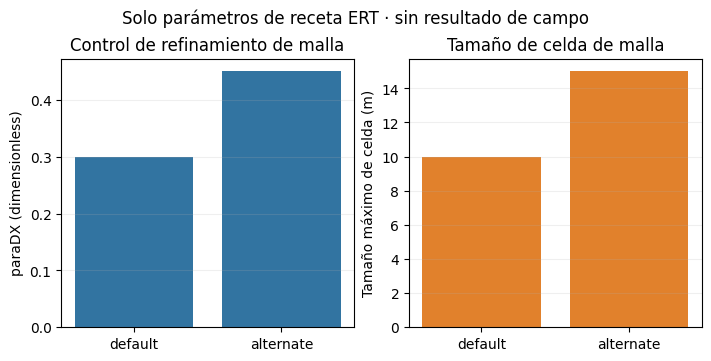

In [7]:
# Lea del AST del código los parámetros de malla predeterminados y alternativos; no se genera malla ni modelo de campo.
import numpy as np
import matplotlib.pyplot as plt
import ert

default = ert.INVERSE_OPTIONS
alternate = ert.ALTERNATE_MESH_OPTIONS
labels = ["default", "alternate"]
dx = [default["paraDX"], alternate["paraDX"]]
cell = [default["paraMaxCellSize"], alternate["paraMaxCellSize"]]
print(
    "paraDX",
    dx,
    "adimensional; tamaño máximo de celda",
    cell,
    "m; razones alternativa/predeterminada",
    cell[1] / cell[0],
    dx[1] / dx[0],
)
fig, ax = plt.subplots(1, 2, figsize=(7, 3.5), constrained_layout=True)
x = np.arange(2)
ax[0].bar(x, dx, color="#3274a1")
ax[0].set(xticks=x, xticklabels=labels, ylabel="paraDX (dimensionless)", title="Control de refinamiento de malla")
ax[1].bar(x, cell, color="#e1812c")
ax[1].set(xticks=x, xticklabels=labels, ylabel="Tamaño máximo de celda (m)", title="Tamaño de celda de malla")
[a.grid(axis="y", alpha=0.2) for a in ax]
fig.suptitle("Solo parámetros de receta ERT · sin resultado de campo")
plt.show()


La fuente Slagdump revisada solo permite enlace al proveedor y en este checkout faltan los bytes .ohm crudos. Los conteos upstream no pueden convertirse en posiciones de electrodos, resistencias, reciprocidad o inversión de campo. No se debe dibujar una pseudosección de Slagdump con valores inventados o sustituidos. El ejemplo fundamental utiliza una muestra Wenner original y sintética con semilla para ejecutar el parser estricto, calcular geometría de resistividad aparente y marcar controles QC. El factor de semiespacio homogéneo es diagnóstico; la topografía y heterogeneidad impiden leerlo como resistividad localizada a cierta profundidad. Derechos, identidad de bytes, marco y error forman parte del análisis.
El control M07 construye superficie irregular y conductor limitado, calcula respuesta directa por elementos finitos, añade ruido con semilla e invoca el pipeline real del producto. La inversa usa factores topográficos y modelo 2D suave pyGIMLi. La reserva intercalada evalúa interpolación entre cuadripolos omitidos; el bloque espacial prueba extrapolación. Ambas se comparan con líneas base homogéneas ajustadas solo al entrenamiento. La verdad conocida es válida porque se regenera el caso sintético. El mapa de cobertura representa sensibilidad del Jacobiano, no resolución. Una sola métrica favorable en este caso no calibra datos de campo; variaciones de malla y error muestran dependencia del resultado respecto de discretización y pesos.

## Resumen

El control analítico verifica parser y factor geométrico bajo la hipótesis de semiespacio homogéneo. No valida Slagdump: sin registros crudos de electrodos y resistencia no corresponde crear pseudosección, revisar reciprocidad o invertir datos de campo.



## Referencias

- [https://www.pygimli.org/user-guide/inversion/](https://www.pygimli.org/user-guide/inversion/)
- [https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/](https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/)